# 23CSE301 Machine Learning — Capstone Project: Review 2
## Notebook 3 of 3 · Clustering Track
**Project**: Food Delivery Duration Prediction & Service Delay Classification Pipeline
**Dataset**: Food Delivery Logistics Dataset (`train.csv`)
**Goal**: Find natural groups of delivery orders **without using any labels**, then check afterwards whether these groups relate to delivery time and SLA delay.

| Review 2 rubric item | Where it is covered |
|---|---|
| **B1** Both clustering algorithms fitted, labels obtained | Sections 3 and 4 |
| **B2** Silhouette, Davies-Bouldin, Calinski-Harabasz for all algorithms; Elbow curve; Dendrogram | Sections 3.1, 4.1, 4.2, 5 |
| **B3** PCA 2-D plot for every algorithm; t-SNE for at least one | Section 6 |
| **C1** Clean, modular, commented code | Whole notebook |

> **No-label rule (Guideline 3.3):** `Time_taken` and `Is_Delayed` are **never** passed to any clustering model. They are only used in Section 7 to interpret the clusters after fitting.

---
### 0. Environment setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
print('Libraries loaded.')

Libraries loaded.


### 1. Data preparation (same pipeline as Review 1)
The same cleaning and feature-engineering functions used in the regression and classification notebooks are reused here.

In [2]:
# ---------------------------------------------------------------------------
# Shared data-preparation functions (identical across regression, classification
# and clustering notebooks so every track uses exactly the same cleaned data).
# ---------------------------------------------------------------------------
import os

RANDOM_STATE = 42
DATA_CANDIDATES = ['train.csv', 'data/train.csv', '../data/train.csv']


def load_raw_data():
    """Load train.csv from the notebook folder or the repo's data/ folder."""
    for path in DATA_CANDIDATES:
        if os.path.exists(path):
            return pd.read_csv(path)
    raise FileNotFoundError(f'train.csv not found in any of {DATA_CANDIDATES}')


def haversine_dist(lon1, lat1, lon2, lat2):
    """Vectorised great-circle distance in km between two sets of coordinates."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def clean_and_engineer(df_raw, verbose=True):
    """Review 1 cleaning + feature-engineering pipeline, wrapped as one function."""
    df = df_raw.copy()

    # 1. Targets: numeric delivery time (regression) and SLA-breach flag (classification)
    df['Time_taken'] = df['Time_taken(min)'].astype(str).str.extract(r'(\d+)')[0].astype(float)
    df['Is_Delayed'] = (df['Time_taken'] > 25.0).astype(int)

    # 2. Strip whitespace and turn hidden 'NaN' string tokens into real missing values
    text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip().replace({'NaN': np.nan, 'nan': np.nan, '': np.nan})
    df['Weatherconditions'] = (df['Weatherconditions'].str.replace('conditions ', '', regex=False)
                               .replace({'NaN': np.nan, 'nan': np.nan}))

    # 3. Numeric casting and rating outliers (ratings > 5 are data-entry errors)
    for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    n_rating_outliers = int((df['Delivery_person_Ratings'] > 5.0).sum())
    df.loc[df['Delivery_person_Ratings'] > 5.0, 'Delivery_person_Ratings'] = 5.0

    # 4. Haversine distance; invalid (near-zero) coordinates replaced by the median distance
    lat1, lon1 = df['Restaurant_latitude'].abs(), df['Restaurant_longitude'].abs()
    lat2, lon2 = df['Delivery_location_latitude'].abs(), df['Delivery_location_longitude'].abs()
    df['distance_km'] = haversine_dist(lon1, lat1, lon2, lat2)
    valid = (lat1 > 1.0) & (lon1 > 1.0) & (lat2 > 1.0) & (lon2 > 1.0)
    df.loc[~valid, 'distance_km'] = df.loc[valid, 'distance_km'].median()

    # 5. Kitchen preparation time (order placed -> order picked up), overnight wrap fixed
    t_order = pd.to_datetime(df['Order_Date'] + ' ' + df['Time_Orderd'], format='%d-%m-%Y %H:%M:%S', errors='coerce')
    t_picked = pd.to_datetime(df['Order_Date'] + ' ' + df['Time_Order_picked'], format='%d-%m-%Y %H:%M:%S', errors='coerce')
    prep = (t_picked - t_order).dt.total_seconds() / 60.0
    prep = prep.where(prep >= 0, prep + 1440.0)
    df['prep_time_min'] = prep.fillna(prep.median())

    # 6. Temporal features
    df['order_hour'] = t_order.dt.hour.fillna(17)
    df['is_rush_hour'] = df['order_hour'].isin([12, 13, 14, 19, 20, 21]).astype(int)
    order_date = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y', errors='coerce')
    df['day_of_week'] = order_date.dt.dayofweek.fillna(2)
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
    df['Festival_binary'] = (df['Festival'] == 'Yes').astype(int)

    # 7. Ordinal traffic level (used by the clustering track)
    df['traffic_level'] = df['Road_traffic_density'].map({'Low': 0, 'Medium': 1, 'High': 2, 'Jam': 3})

    if verbose:
        print(f'Rows: {len(df):,} | rating outliers capped: {n_rating_outliers} | '
              f'coordinate anomalies fixed: {int((~valid).sum())} | duplicate IDs: {int(df["ID"].duplicated().sum())}')
    return df


NUMERICAL_COLS = ['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'prep_time_min',
                  'order_hour', 'Vehicle_condition', 'multiple_deliveries', 'Festival_binary',
                  'is_rush_hour', 'is_weekend']
CATEGORICAL_COLS = ['Weatherconditions', 'Road_traffic_density', 'City', 'Type_of_vehicle']


def build_preprocessor():
    """Median-impute + scale numerics; mode-impute + one-hot categoricals. Fit on TRAIN only."""
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))])
    return ColumnTransformer([('num', num_pipe, NUMERICAL_COLS), ('cat', cat_pipe, CATEGORICAL_COLS)])


def get_feature_names(preprocessor):
    cat_names = preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(CATEGORICAL_COLS)
    return NUMERICAL_COLS + list(cat_names)

df = clean_and_engineer(load_raw_data())

Rows: 45,593 | rating outliers capped: 53 | coordinate anomalies fixed: 3640 | duplicate IDs: 0


### 2. Choosing the clustering features
Distance-based clustering (K-Means and Ward linkage) works best on **continuous or ordinal** features on a common scale. One-hot dummies make all points look equally far apart and dominate the Euclidean distance, so they are left out. The 8 features below describe the **rider, the route and the operating conditions** of each order:

| Feature | Meaning |
|---|---|
| `Delivery_person_Age`, `Delivery_person_Ratings` | Who delivers the order |
| `Vehicle_condition`, `multiple_deliveries` | Rider's vehicle and workload |
| `distance_km`, `prep_time_min` | Route length and kitchen delay |
| `order_hour`, `traffic_level` | When the order is placed and how congested the road is (Low=0 … Jam=3) |

As in the other tracks, we use the **same 80:20 split**. The imputer and scaler are fitted on the training partition only, and clustering is performed on that partition.

In [3]:
CLUSTER_FEATURES = ['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'prep_time_min',
                    'order_hour', 'Vehicle_condition', 'multiple_deliveries', 'traffic_level']

train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE, stratify=df['Is_Delayed'])

cluster_prep = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
X_clu = cluster_prep.fit_transform(train_df[CLUSTER_FEATURES])     # fit on TRAIN only
X_clu_test = cluster_prep.transform(test_df[CLUSTER_FEATURES])     # used later to check K-Means generalises

# Silhouette and hierarchical clustering are O(n^2), so all metrics are computed on one fixed
# 5,000-row evaluation sample shared by every algorithm (fair comparison).
eval_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_clu), 5000, replace=False)
X_eval = X_clu[eval_idx]
print(f'Clustering matrix: {X_clu.shape} | evaluation sample: {X_eval.shape}')


def cluster_metrics(X, labels):
    """The three mandatory internal validation metrics for one set of cluster labels."""
    return {'Silhouette (↑)': silhouette_score(X, labels),
            'Davies-Bouldin (↓)': davies_bouldin_score(X, labels),
            'Calinski-Harabasz (↑)': calinski_harabasz_score(X, labels)}

Clustering matrix: (36474, 8) | evaluation sample: (5000, 8)


---
### 3. Algorithm 1 — K-Means clustering
K-Means places *k* centroids and repeatedly assigns each order to the nearest centroid and moves each centroid to the mean of its orders. This minimises the **within-cluster sum of squares (inertia)**. Because *k* must be chosen in advance, we scan k = 2 … 10.

#### 3.1 Elbow curve (inertia vs. k) with silhouette check  [Rubric B2]

,Inertia,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
k,,,,
2,246860.5746,0.1547,2.0469,932.9909
3,220752.9746,0.1535,2.2361,807.9453
4,203749.9257,0.1500,2.0323,719.9304
5,191960.1123,0.1339,1.9715,652.7438
6,183507.6513,0.1287,1.9167,591.3985
7,176399.6627,0.1231,1.8962,548.8343
8,170023.6256,0.1219,1.9656,514.7537
9,163657.6955,0.1265,1.8723,495.7689
10,158376.2532,0.1258,1.9961,470.1187


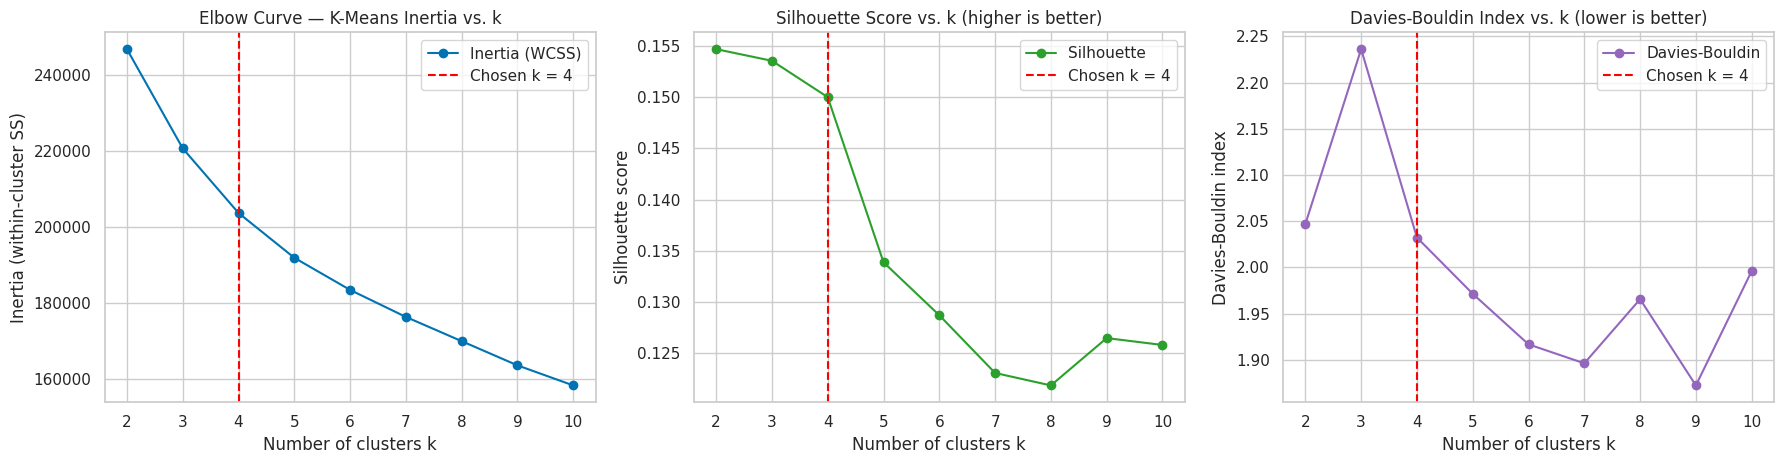

In [4]:
k_range = range(2, 11)
elbow_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_clu)
    elbow_rows.append({'k': k, 'Inertia': km.inertia_, **cluster_metrics(X_eval, km.predict(X_eval))})
elbow_df = pd.DataFrame(elbow_rows).set_index('k')
display(elbow_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(elbow_df.index, elbow_df['Inertia'], marker='o', label='Inertia (WCSS)')
axes[0].axvline(4, color='red', linestyle='--', label='Chosen k = 4')
axes[0].set_title('Elbow Curve — K-Means Inertia vs. k')
axes[0].set_xlabel('Number of clusters k')
axes[0].set_ylabel('Inertia (within-cluster SS)')
axes[0].legend()

axes[1].plot(elbow_df.index, elbow_df['Silhouette (↑)'], marker='o', color='tab:green', label='Silhouette')
axes[1].axvline(4, color='red', linestyle='--', label='Chosen k = 4')
axes[1].set_title('Silhouette Score vs. k (higher is better)')
axes[1].set_xlabel('Number of clusters k')
axes[1].set_ylabel('Silhouette score')
axes[1].legend()

axes[2].plot(elbow_df.index, elbow_df['Davies-Bouldin (↓)'], marker='o', color='tab:purple', label='Davies-Bouldin')
axes[2].axvline(4, color='red', linestyle='--', label='Chosen k = 4')
axes[2].set_title('Davies-Bouldin Index vs. k (lower is better)')
axes[2].set_xlabel('Number of clusters k')
axes[2].set_ylabel('Davies-Bouldin index')
axes[2].legend()
plt.tight_layout()
plt.show()

#### Observation 3.1: Choosing k
- **The elbow is gradual, not sharp.** Inertia falls by 26.1k (k=2→3), 17.0k (3→4), 11.8k (4→5), then only 8.5k and 7.1k. The curve flattens clearly after **k = 4–5**, so extra clusters after that mostly split existing groups.
- **Silhouette stays flat up to k = 4 (0.155 → 0.154 → 0.150) and then drops** to 0.134 at k = 5 and about 0.12 after. So k = 4 costs almost nothing in cohesion compared with k = 2, but k = 5 does.
- **Davies-Bouldin at k = 4 (2.03) is the best of k = 2–4.** Calinski-Harabasz always favours the smallest k on this data, so it is not decisive.
- **Decision: k = 4.** It sits at the end of the elbow, keeps silhouette at its plateau, and (Section 7) produces four segments that are easy to explain. k = 2 would only separate "short daytime" from "everything else".
- Silhouette values around 0.15 mean the groups **overlap**. Delivery orders form a continuum and have no natural gaps, which is common for real operational data. The value of clustering here is **segmentation**, not finding perfectly separated blobs.

#### 3.2 Final K-Means model (k = 4)

In [5]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_clu)
train_df['kmeans_cluster'] = kmeans.labels_
kmeans_eval_labels = kmeans.predict(X_eval)

print('K-Means cluster sizes (training partition):')
print(train_df['kmeans_cluster'].value_counts().sort_index().to_string())

# Generalisation check: assign held-out test orders to the learned centroids and score them
test_labels = kmeans.predict(X_clu_test)
print(f"\nSilhouette on 5,000 train rows : {silhouette_score(X_eval, kmeans_eval_labels):.4f}")
print(f"Silhouette on held-out test set: {silhouette_score(X_clu_test[:5000], test_labels[:5000]):.4f}")

K-Means cluster sizes (training partition):
kmeans_cluster
0    12753
1    10354
2     4142
3     9225



Silhouette on 5,000 train rows : 0.1500


Silhouette on held-out test set: 0.1492


---
### 4. Algorithm 2 — Agglomerative hierarchical clustering
Agglomerative clustering starts with every order as its own cluster and repeatedly merges the two closest clusters. The **linkage** decides what "closest" means:
- **Ward**: merge the pair that increases total within-cluster variance the least (same objective as K-Means),
- **Complete**: distance between the two *farthest* points,
- **Average**: mean distance over all cross-cluster pairs,
- **Single**: distance between the two *closest* points (prone to "chaining").

It needs the full pairwise-distance matrix (O(n²) memory), so it is fitted on the 5,000-order evaluation sample.

#### 4.1 Dendrogram (Ward linkage)  [Rubric B2]

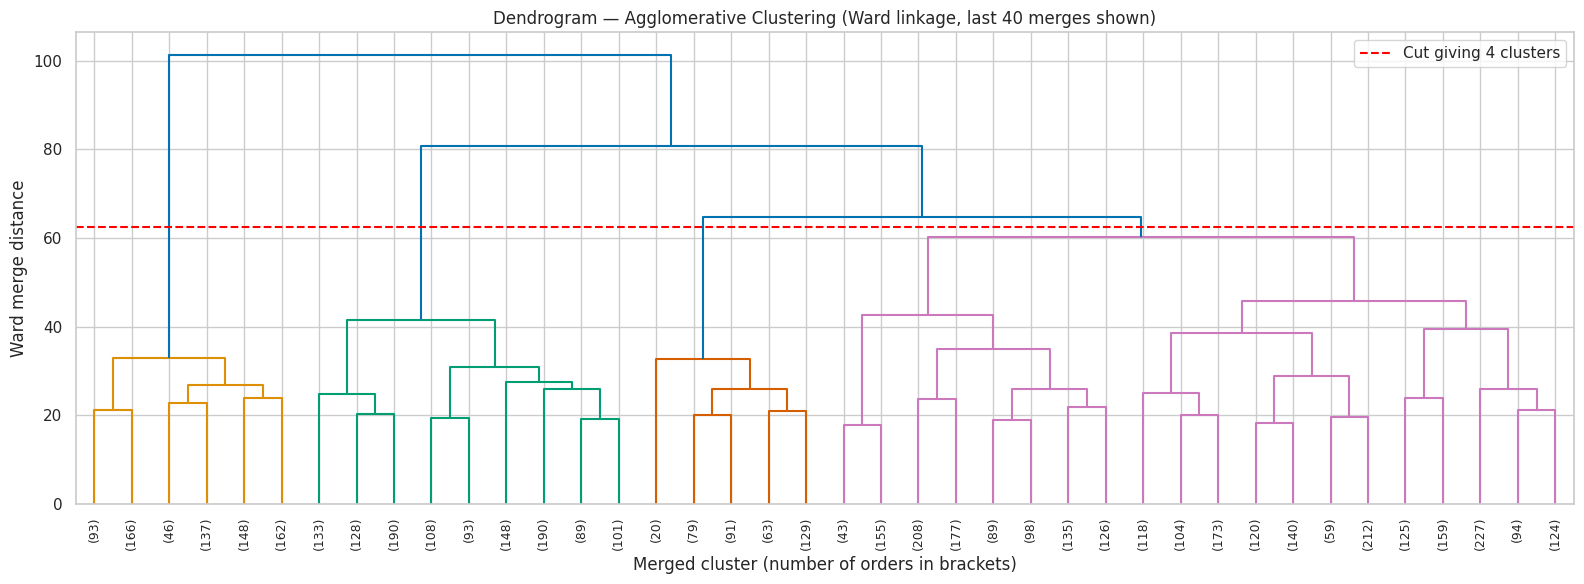

Largest 10 merge distances (top of the tree): [101.4  80.9  64.7  60.3  45.8  42.7  41.5  39.4  38.5  34.9]


In [6]:
Z = linkage(X_eval, method='ward')
cut_height = (Z[-K, 2] + Z[-(K - 1), 2]) / 2      # horizontal cut between the merges that give K clusters

fig, ax = plt.subplots(figsize=(16, 6))
dendrogram(Z, truncate_mode='lastp', p=40, show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=9, ax=ax, color_threshold=cut_height)
ax.axhline(cut_height, color='red', linestyle='--', label=f'Cut giving {K} clusters')
ax.set_title('Dendrogram — Agglomerative Clustering (Ward linkage, last 40 merges shown)')
ax.set_xlabel('Merged cluster (number of orders in brackets)')
ax.set_ylabel('Ward merge distance')
ax.legend()
plt.tight_layout()
plt.show()

# The biggest jumps in merge distance show where a cut separates well-distinct groups
last_merges = Z[-10:, 2][::-1]
print('Largest 10 merge distances (top of the tree):', np.round(last_merges, 1))

#### Observation 4.1: Reading the dendrogram
- The last merges happen at heights **101.4, 80.9, 64.7, 60.3** and then 45.8. Cutting between 60.3 and 64.7 (red line) gives the **4 clusters** used for K-Means, so both algorithms are compared at the same k.
- The biggest jump (101.4 vs 80.9) is at the very top. This means the strongest split in the data is a **2-way split**: the short, early-morning, low-traffic orders (left orange branch) versus the rest.
- The gap between 64.7 and 60.3 is small, so the 4- and 5-cluster solutions are close. This is the same "soft elbow" seen for K-Means, now from a different algorithm.

#### 4.2 Comparing linkage strategies  [Rubric B2]

In [7]:
linkage_rows, agglo_labels = [], {}
for link in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(X_eval)
    agglo_labels[link] = labels
    sizes = np.bincount(labels)
    linkage_rows.append({'Linkage': link, **cluster_metrics(X_eval, labels),
                         'Cluster sizes': sorted(sizes.tolist(), reverse=True),
                         'Smallest cluster (%)': 100 * sizes.min() / len(labels)})
linkage_df = pd.DataFrame(linkage_rows).set_index('Linkage')
display(linkage_df)

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Cluster sizes,Smallest cluster (%)
Linkage,,,,,
ward,0.1263,2.0916,593.3379,"[2686, 1180, 752, 382]",7.6400
complete,0.1452,1.4765,148.5887,"[4629, 334, 34, 3]",0.0600
average,0.4186,0.6690,51.6491,"[4976, 17, 4, 3]",0.0600
single,0.3625,0.4866,26.6827,"[4992, 4, 3, 1]",0.0200


#### Observation 4.2: Comparing linkage strategies
- **Average and single linkage look best on paper** (silhouette 0.42 / 0.36, Davies-Bouldin 0.67 / 0.49), **but they are degenerate.** One cluster holds 4,976 or 4,992 of the 5,000 orders, and the other "clusters" are 1–17 outlier points. Single linkage chains everything together through nearest neighbours, and average linkage behaves similarly on dense data.
- **Complete linkage** has the same problem (4,629 / 334 / 34 / 3).
- **Calinski-Harabasz shows the problem** (27–149 against 593 for Ward), because it rewards large between-cluster spread across the whole dataset.
- **Ward is the only linkage giving usable, balanced groups** (smallest cluster 7.6%). It is selected as the hierarchical model.
- **Lesson:** a high silhouette score alone can be misleading. Always check cluster sizes next to the metrics.

In [8]:
# Final hierarchical model: Ward linkage, k = 4
agglo = AgglomerativeClustering(n_clusters=K, linkage='ward')
agglo_eval_labels = agglo.fit_predict(X_eval)
print('Agglomerative (Ward) cluster sizes:', np.bincount(agglo_eval_labels).tolist())

Agglomerative (Ward) cluster sizes: [2686, 752, 1180, 382]


---
### 5. Evaluation summary — both algorithms  [Rubric B2 / Deliverable D3]
Both models are scored on the **same 5,000 orders**, so the numbers can be compared directly.

In [9]:
summary_df = pd.DataFrame({
    'K-Means (k=4)': cluster_metrics(X_eval, kmeans_eval_labels),
    'Agglomerative – Ward (k=4)': cluster_metrics(X_eval, agglo_eval_labels),
}).T
summary_df['Agreement with K-Means (ARI)'] = [1.0, adjusted_rand_score(kmeans_eval_labels, agglo_eval_labels)]
summary_df.index.name = 'Algorithm'
display(summary_df.style.format('{:.4f}').set_caption('Internal validation metrics (5,000-order evaluation sample)'))

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Agreement with K-Means (ARI)
Algorithm,,,,
K-Means (k=4),0.1500,2.0323,719.9304,1.0000
Agglomerative – Ward (k=4),0.1263,2.0916,593.3379,0.1492


#### Observation 5: K-Means vs. Agglomerative (Ward)
| Metric | K-Means | Ward | Better |
|---|---|---|---|
| Silhouette (↑) | **0.150** | 0.126 | K-Means |
| Davies-Bouldin (↓) | **2.032** | 2.092 | K-Means |
| Calinski-Harabasz (↑) | **720** | 593 | K-Means |

- **K-Means wins on all three internal metrics.** This is expected: K-Means directly minimises within-cluster variance, which is what all three metrics reward. Ward optimises the same quantity only greedily, one merge at a time, and can never undo an early merge.
- The **ARI between the two partitions is only 0.149**, so they split the orders differently. Ward separates orders with **zero** multiple deliveries and a small group of early-morning trips. K-Means cuts mainly by time of day, traffic and rider quality (Section 7).
- K-Means also **generalises**: held-out test orders assigned to the learned centroids have silhouette 0.149, the same as the training sample (0.150).

---
### 6. Cluster visualisation  [Rubric B3]
#### 6.1 PCA (2 principal components) — every algorithm
PCA is fitted on the scaled clustering features and used only to project the orders to 2-D for plotting. The clustering itself was done in the full 8-D space.

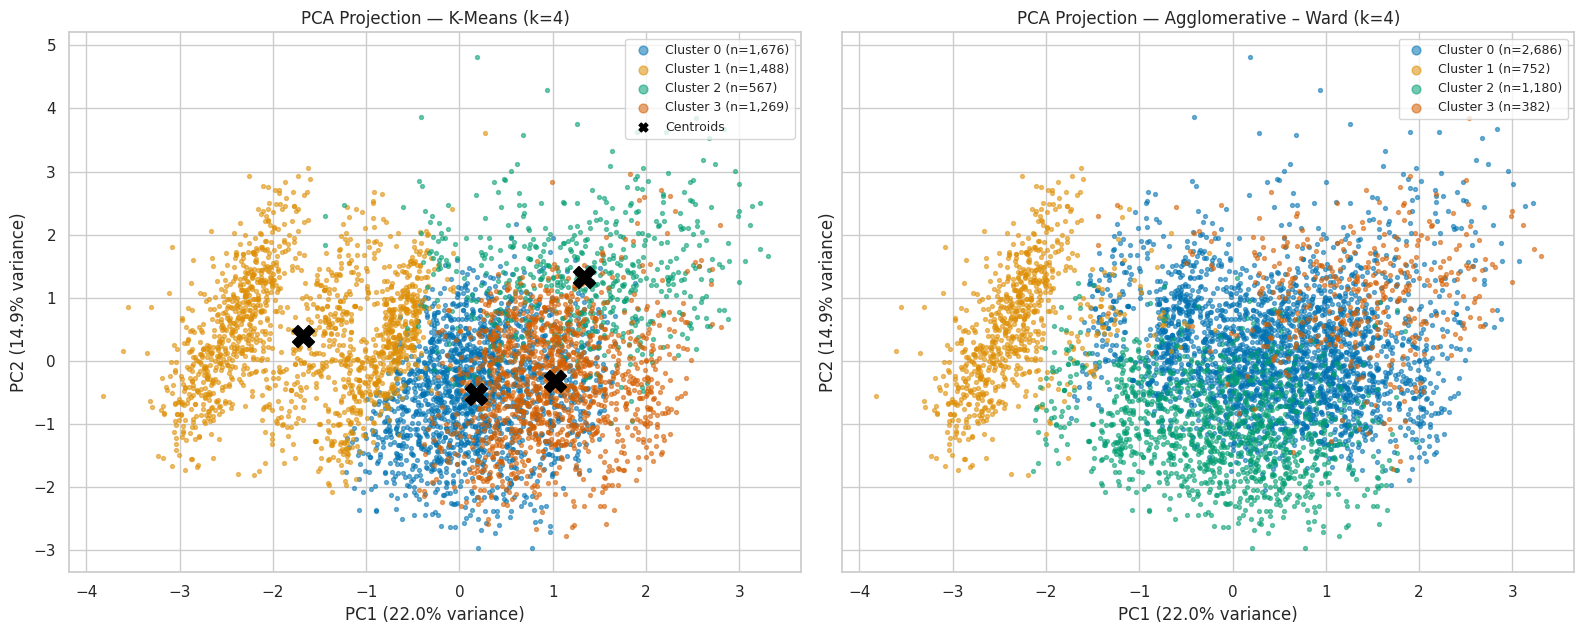

,PC1,PC2
Delivery_person_Age,+0.051,+0.518
Delivery_person_Ratings,-0.199,-0.428
distance_km,+0.599,-0.209
prep_time_min,-0.004,-0.061
order_hour,+0.595,-0.266
Vehicle_condition,-0.033,-0.351
multiple_deliveries,+0.267,+0.554
traffic_level,+0.416,+0.030


In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_clu)
X_eval_2d = pca.transform(X_eval)
centroids_2d = pca.transform(kmeans.cluster_centers_)
var = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True, sharey=True)
panels = [('K-Means (k=4)', kmeans_eval_labels), ('Agglomerative – Ward (k=4)', agglo_eval_labels)]
for ax, (title, labels) in zip(axes, panels):
    for c in range(K):
        m = labels == c
        ax.scatter(X_eval_2d[m, 0], X_eval_2d[m, 1], s=8, alpha=0.55, label=f'Cluster {c} (n={m.sum():,})',
                   color=sns.color_palette('colorblind')[c])
    ax.set_title(f'PCA Projection — {title}')
    ax.set_xlabel(f'PC1 ({var[0]:.1f}% variance)')
    ax.set_ylabel(f'PC2 ({var[1]:.1f}% variance)')
axes[0].scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=250, c='black', label='Centroids')
for ax in axes:
    leg = ax.legend(loc='upper right', fontsize=9)
    for h in leg.legend_handles:
        h.set_sizes([40])          # uniform legend marker size
plt.tight_layout()
plt.show()

# What do the two principal components represent?
loadings = pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES, columns=['PC1', 'PC2'])
display(loadings.style.format('{:+.3f}').background_gradient(cmap='RdBu_r', vmin=-0.7, vmax=0.7))

#### Observation 6.1: PCA view
- The first two components explain **36.9% of the variance** (PC1 22.0%, PC2 14.9%). Much of the structure lives in the other six dimensions, so some overlap in 2-D is expected.
- **PC1 is a "long evening congested trip" axis**: `distance_km` (+0.60), `order_hour` (+0.60), `traffic_level` (+0.42).
- **PC2 is a "rider workload and quality" axis**: `multiple_deliveries` (+0.55) and `Delivery_person_Age` (+0.52) against `Delivery_person_Ratings` (−0.43) and `Vehicle_condition` (−0.35).
- In the K-Means plot, **cluster 1** (short daytime trips) is clearly separated at low PC1. **Cluster 2** (older, low-rated, overloaded riders) rises along PC2. Clusters 0 and 3 sit side by side along PC1 and differ mainly in traffic level.
- Ward's clusters overlap much more in this projection. This matches its lower silhouette score.

#### 6.2 t-SNE projection — K-Means and Agglomerative
t-SNE is a non-linear embedding that keeps local neighbourhoods. It often shows cluster shapes that the linear PCA projection squashes together. It is run on 3,000 of the evaluation orders (t-SNE is slow and only for visualisation).

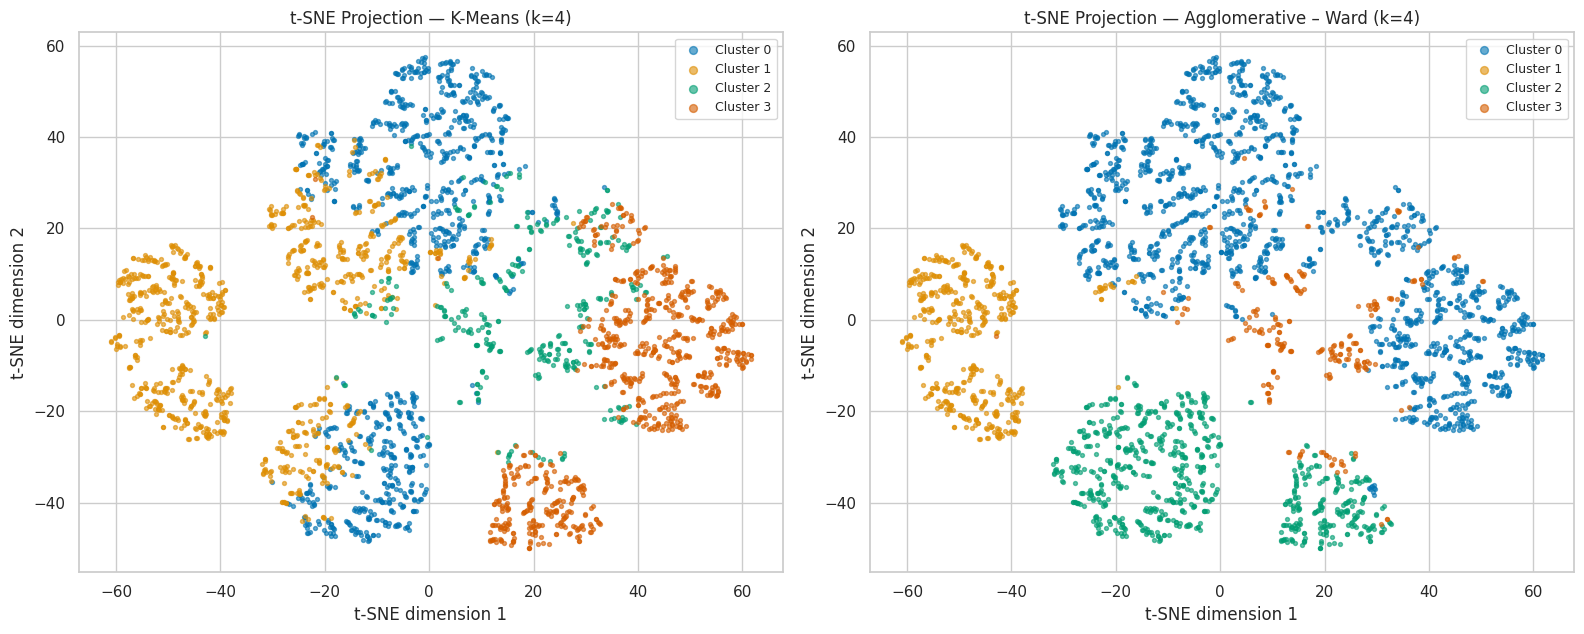

In [11]:
tsne_n = 3000
X_tsne = TSNE(n_components=2, perplexity=40, init='pca', random_state=RANDOM_STATE).fit_transform(X_eval[:tsne_n])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (title, labels) in zip(axes, panels):
    for c in range(K):
        m = labels[:tsne_n] == c
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=8, alpha=0.6, label=f'Cluster {c}',
                   color=sns.color_palette('colorblind')[c])
    ax.set_title(f't-SNE Projection — {title}')
    ax.set_xlabel('t-SNE dimension 1')
    ax.set_ylabel('t-SNE dimension 2')
    ax.legend(loc='upper right', fontsize=9, markerscale=2)
plt.tight_layout()
plt.show()

#### Observation 6.2: t-SNE view
- t-SNE shows a set of **separate "islands"** that PCA hides. They come from the discrete-valued features (traffic level 0–3, multiple deliveries 0–3, vehicle condition 0–3): orders with the same combination sit close together.
- **Ward follows these islands more closely.** For example, its cluster 2 (all orders with zero multiple deliveries) sits on the bottom islands. K-Means sometimes cuts across an island because it looks for round clusters of similar size in the full feature space.
- This explains the trade-off: **K-Means gives the best global compactness scores, while Ward respects local neighbourhoods more**. Neither gives cleanly separated clusters, which is consistent with silhouette ≈ 0.15.

---
### 7. Interpreting the clusters (labels used only after fitting)
Now we compare the K-Means segments with the ground-truth delivery time and the `Is_Delayed` flag. These were **not** used during fitting. This is the validation step allowed by Guideline 3.3.

,Orders,Delivery_person_Age,Delivery_person_Ratings,distance_km,prep_time_min,order_hour,Vehicle_condition,multiple_deliveries,traffic_level,Time_taken,Delay rate
kmeans_cluster,,,,,,,,,,,
0,"12,753",29.03,4.73,11.93,10.03,20.00,1.05,0.66,0.48,23.65,0.38
1,"10,354",29.63,4.69,4.14,9.97,11.17,1.01,0.64,0.80,22.32,0.34
2,"4,142",32.65,4.00,12.49,9.90,19.23,0.97,1.16,1.93,37.36,0.98
3,"9,225",28.70,4.72,11.49,9.99,19.97,1.01,0.78,2.99,29.34,0.64


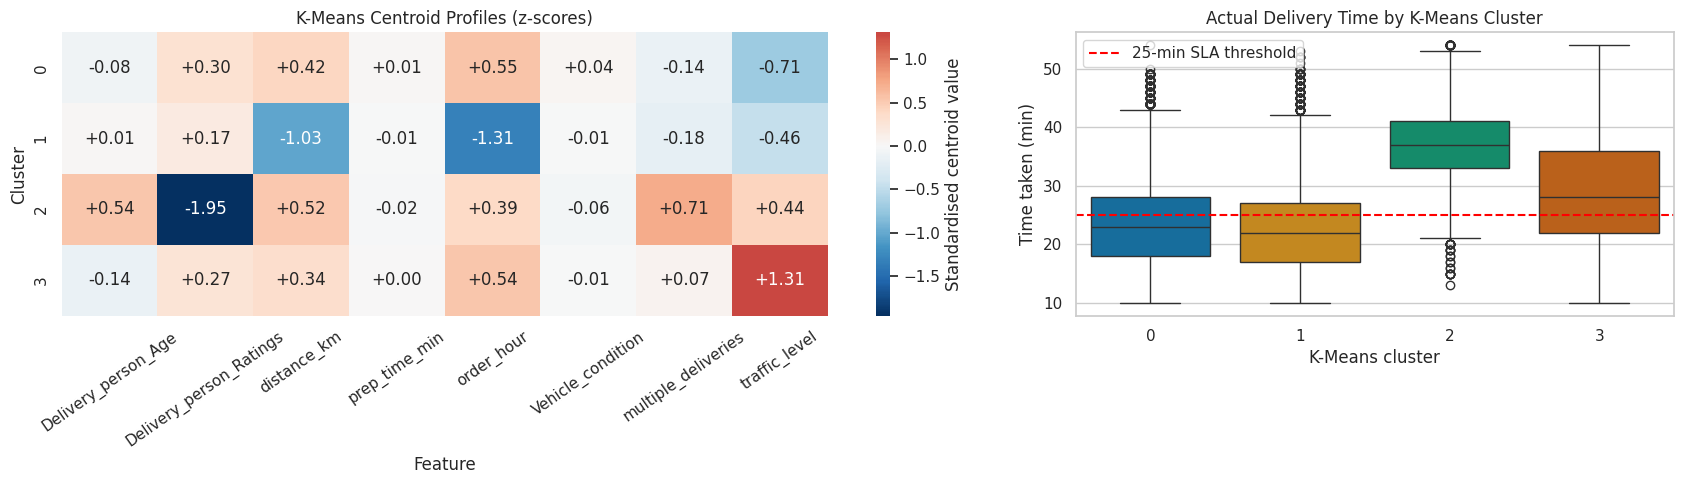

In [12]:
profile = (train_df.groupby('kmeans_cluster')[CLUSTER_FEATURES + ['Time_taken', 'Is_Delayed']].mean()
           .rename(columns={'Is_Delayed': 'Delay rate'}))
profile.insert(0, 'Orders', train_df['kmeans_cluster'].value_counts().sort_index())
display(profile.style.format({c: '{:.2f}' for c in profile.columns if c != 'Orders'} | {'Orders': '{:,}'})
        .background_gradient(cmap='Oranges', subset=['Time_taken', 'Delay rate']))

# Standardised centroids: how far (in std units) each cluster sits from the average order
centroid_df = pd.DataFrame(kmeans.cluster_centers_, columns=CLUSTER_FEATURES)
centroid_df.index.name = 'Cluster'
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1.6, 1]})
sns.heatmap(centroid_df, annot=True, fmt='+.2f', cmap='RdBu_r', center=0, ax=axes[0],
            cbar_kws={'label': 'Standardised centroid value'})
axes[0].set_title('K-Means Centroid Profiles (z-scores)')
axes[0].tick_params(axis='x', rotation=35)
axes[0].set_xlabel('Feature')
axes[0].set_ylabel('Cluster')

sns.boxplot(data=train_df, x='kmeans_cluster', y='Time_taken', ax=axes[1], palette='colorblind')
axes[1].axhline(25, color='red', linestyle='--', label='25-min SLA threshold')
axes[1].set_title('Actual Delivery Time by K-Means Cluster')
axes[1].set_xlabel('K-Means cluster')
axes[1].set_ylabel('Time taken (min)')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

In [13]:
# Same post-hoc check for the Agglomerative (Ward) clusters on the 5,000-order sample
eval_orders = train_df.iloc[eval_idx]
agglo_profile = (eval_orders.assign(agglo_cluster=agglo_eval_labels)
                 .groupby('agglo_cluster')[CLUSTER_FEATURES + ['Time_taken', 'Is_Delayed']].mean()
                 .rename(columns={'Is_Delayed': 'Delay rate'}))
agglo_profile.insert(0, 'Orders', np.bincount(agglo_eval_labels))
display(agglo_profile.style.format({c: '{:.2f}' for c in agglo_profile.columns if c != 'Orders'})
        .background_gradient(cmap='Oranges', subset=['Time_taken', 'Delay rate']))

# How well does each clustering line up with the SLA label? (ARI: 0 = random, 1 = identical)
print(f"ARI K-Means vs Is_Delayed      : {adjusted_rand_score(eval_orders['Is_Delayed'], kmeans_eval_labels):.4f}")
print(f"ARI Agglomerative vs Is_Delayed: {adjusted_rand_score(eval_orders['Is_Delayed'], agglo_eval_labels):.4f}")
print(f"ARI K-Means vs traffic_level   : {adjusted_rand_score(eval_orders['traffic_level'].fillna(-1), kmeans_eval_labels):.4f}")

,Orders,Delivery_person_Age,Delivery_person_Ratings,distance_km,prep_time_min,order_hour,Vehicle_condition,multiple_deliveries,traffic_level,Time_taken,Delay rate
agglo_cluster,,,,,,,,,,,
0,2686,29.79,4.69,10.55,10.02,18.68,1.01,1.09,1.69,28.09,0.59
1,752,29.03,4.67,3.41,9.83,8.68,0.90,0.61,0.09,19.91,0.19
2,1180,28.38,4.71,10.01,10.11,18.94,1.12,0.00,1.42,22.66,0.34
3,382,31.78,3.92,13.55,9.69,19.50,1.01,0.89,1.72,35.94,0.94


ARI K-Means vs Is_Delayed      : 0.0578
ARI Agglomerative vs Is_Delayed: 0.0585
ARI K-Means vs traffic_level   : 0.3900


#### Observation 7: What the clusters mean (validated with labels after fitting)
**K-Means segments (training partition, 36,474 orders):**

| Cluster | Size | Profile | Mean time | Delay rate |
|---|---|---|---|---|
| 1 | 10,354 | **Short daytime trips**: ~11:00, 4.1 km, light traffic | 22.3 min | 34% |
| 0 | 12,753 | **Evening long trips on clear roads**: ~20:00, 11.9 km, low traffic, good riders | 23.7 min | 38% |
| 3 | 9,225 | **Evening traffic-jam trips**: ~20:00, 11.5 km, traffic level 3.0 (Jam) | 29.3 min | 64% |
| 2 | 4,142 | **At-risk riders**: older (32.6 yrs), rated 4.00, 1.16 multiple deliveries, high traffic | 37.4 min | **98%** |

- **Delay rate ranges from 34% to 98% across the clusters, even though no labels were used.** The algorithm found operationally meaningful segments on its own. Cluster 2 is almost a "guaranteed breach" group: dispatch rules could avoid giving extra orders to low-rated riders at peak times.
- Ward finds a similar high-risk group (cluster 3: rating 3.92, 94% delayed) and a very safe early-morning group (cluster 1: 08:40, 3.4 km, 19% delayed). The same patterns appear with a different algorithm, which supports the result.
- The ARI with `Is_Delayed` is low (about 0.06) for both algorithms. This is expected: clusters describe *types of orders*, not the binary SLA outcome, and a 4-way segmentation cannot match a 2-class label. K-Means clusters do align moderately with traffic level (ARI 0.39).

---
## 8. Observations: which clustering model performs best, and why

### Best model: K-Means (k = 4)
1. **Better on all three mandatory metrics**: Silhouette 0.150 vs 0.126, Davies-Bouldin 2.03 vs 2.09, Calinski-Harabasz 720 vs 593 against the best hierarchical option (Ward).
2. **Its objective matches the data.** After standard scaling, the 8 features are on comparable scales, and the segments are roughly compact groups around a typical order. K-Means optimises exactly that (within-cluster variance), and does it globally with 10 random restarts. Ward optimises the same criterion greedily and cannot undo early merges.
3. **It scales and generalises.** K-Means was trained on all 36,474 training orders (Ward is limited to about 5,000 by its O(n²) distance matrix). It assigns new orders with `predict()`, and keeps the same silhouette on the unseen test set (0.149).
4. **It produces the most useful segments.** The four clusters map to clear delivery situations with delay rates of 34%, 38%, 64% and 98%. That is directly usable for dispatch and SLA planning.

### When Agglomerative clustering would still be preferred
- When the **hierarchy itself** is useful. The dendrogram shows that the main split is short daytime trips versus the rest, and it lets you choose k after fitting.
- When groups follow **local neighbourhood structure** rather than round shapes. t-SNE suggests Ward follows the discrete-feature islands more closely.
- Only **Ward linkage** is suitable here. Single, average and complete linkage produce one giant cluster plus outliers, even though their silhouette scores look higher.

**Conclusion:** K-Means with k = 4 is the recommended clustering model for this dataset. The overall silhouette of about 0.15 shows the segments overlap, so they should be used as *risk profiles* for operations, not as sharply separated classes.